# Models: health care spending, 2023 training and 2024 testing

This notebook fits and compares models for total annual health care spending, using the MEPS Full Year files.

**Design decisions** (from the conclusions in `02_tot_figures.ipynb`). Each one is a default I chose, and each can be changed in the settings cell:

| Decision | Choice | Why |
|---|---|---|
| Target | `TOTEXP23` / `TOTEXP24`, total spending, all payers | The project's question is total cost. `TOTPRV` is listed as an alternative in the conclusions. |
| Population | Adults 18 and over | Diagnosis, lifestyle, and marital questions are adult-only, so one model needs one population. |
| Timing | Concurrent: same-year features predict same-year spending | The features are measured in the year they predict. Training on 2023 and testing on 2024 keeps that structure. |
| Features | Age, sex, region, marital status, poverty ratio, coverage, education (`HIDEG`), self-rated and mental health (round 31), 10 diagnosis flags, smoking, employment (round 31) | See the candidate table in the conclusions. `EDUCYR` and race are left out. |
| Weights | `PERWT23F` / `PERWT24F` in every fit and every average | The weights change the averages by about 11%. |
| Test sets | All 2024 adults, and 2024 adults who weren't in the 2023 panel | About 47% of 2023 people appear again in 2024, so the second set tests on new people. |
| Standard errors | Clustered by `VARSTR` and `VARPSU` in the GLMs | MEPS isn't a simple random sample. |

## 1. Setup

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"  # avoids the OpenMP hang seen on WSL2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_tweedie_deviance, mean_absolute_error
from sklearn.model_selection import train_test_split

from src.load_meps import load_meps

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

SEED = 42
TWEEDIE_POWER = 1.5

## 2. Loading and cleaning

`load_meps` reads each year's file. The loader below renames the year-suffixed columns (for example `AGE23X` and `AGE24X`) to one standard name, so the same code runs for both years. Each feature is then checked against its valid codes, and rows with invalid codes are dropped, with counts printed.

In [2]:
# standard name -> MEPS name, with {y} replaced by the two-digit year
MEPS_COLS = {
    "age": "AGE{y}X", "sex": "SEX", "region": "REGION{y}", "marital": "MARRY{y}X",
    "poverty_ratio": "POVLEV{y}", "coverage": "INSCOV{y}", "education": "HIDEG",
    "rth": "RTHLTH31", "mnh": "MNHLTH31", "smoking": "OFTSMK53", "employment": "EMPST31H",
    "total_exp": "TOTEXP{y}", "weight": "PERWT{y}F", "stratum": "VARSTR", "psu": "VARPSU",
    "person_id": "DUPERSID",
}
# diagnosis flags keep their MEPS names in every year
DX_MAP = {
    "hypertension": "HIBPDX", "chd": "CHDDX", "heart_attack": "MIDX", "stroke": "STRKDX",
    "emphysema": "EMPHDX", "high_chol": "CHOLDX", "cancer": "CANCERDX", "arthritis": "ARTHDX",
    "asthma": "ASTHDX", "diabetes": "DIABDX_M18",
}
DX_FLAGS = list(DX_MAP)

# valid answers for each feature; anything else (-1, -7, -8, -15) is dropped for adults
VALID = {
    "sex": {1, 2}, "region": {1, 2, 3, 4}, "marital": {1, 2, 3, 4, 5},
    "coverage": {1, 2, 3}, "education": {1, 2, 3, 4, 5, 6, 7},
    "rth": {1, 2, 3, 4, 5}, "mnh": {1, 2, 3, 4, 5}, "smoking": {1, 2, 3},
    "employment": {1, 2, 34},
    **{flag: {1, 2} for flag in DX_FLAGS},
}

LABELS = {
    "sex": {1: "Male", 2: "Female"},
    "region": {1: "Northeast", 2: "Midwest", 3: "South", 4: "West"},
    "marital": {1: "Married", 2: "Widowed", 3: "Divorced", 4: "Separated", 5: "Never married"},
    "coverage": {1: "Private", 2: "Public only", 3: "Uninsured"},
    "education": {1: "No degree", 2: "GED", 3: "High school", 4: "Bachelor", 5: "Master",
                  6: "Doctorate", 7: "Other degree"},
    "rth": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "mnh": {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"},
    "smoking": {1: "Every day", 2: "Some days", 3: "Not at all"},
    "employment": {1: "Employed", 2: "Job to return to", 34: "Not employed"},
}

def load_adults(year):
    yy = str(year)[2:]
    cols = {k: v.format(y=yy) for k, v in MEPS_COLS.items()}
    cols.update(DX_MAP)
    raw = load_meps(year, columns=list(cols.values()))
    df = raw.rename(columns={v: k for k, v in cols.items()})
    df["year"] = year
    n_all = len(df)

    df = df[(df["age"] >= 18) & (df["weight"] > 0)].copy()
    n_adult_weighted = len(df)

    dropped = {}
    keep = pd.Series(True, index=df.index)
    for feature, valid in VALID.items():
        bad = ~df[feature].isin(valid)
        dropped[feature] = int((bad & keep).sum())
        keep &= ~bad
    df = df[keep].copy()

    df["any_spend"] = (df["total_exp"] > 0).astype(int)
    for flag in DX_FLAGS:
        df[flag] = (df[flag] == 1).astype(int)
    for feature, labels in LABELS.items():
        df[feature] = df[feature].map(labels)
    df["pov100"] = df["poverty_ratio"] / 100
    df["cost_k"] = df["total_exp"] / 1000  # GLMs fit in thousands of dollars for numerical stability
    df["age2"] = df["age"] ** 2

    report = {"year": year, "all_rows": n_all, "adults_with_weight": n_adult_weighted,
              "kept": len(df), "dropped_by_feature": dropped}
    return df.reset_index(drop=True), report

train_raw, train_report = load_adults(2023)
test_raw, test_report = load_adults(2024)

for rep in (train_report, test_report):
    print(f"{rep['year']}: {rep['all_rows']:,} rows, {rep['adults_with_weight']:,} adults with weight > 0, "
          f"{rep['kept']:,} kept after valid-code checks")
    print("   dropped by feature:", {k: v for k, v in rep["dropped_by_feature"].items() if v})

2023: 18,919 rows, 14,768 adults with weight > 0, 14,299 kept after valid-code checks
   dropped by feature: {'marital': 1, 'education': 134, 'rth': 36, 'mnh': 18, 'smoking': 181, 'hypertension': 83, 'chd': 2, 'stroke': 2, 'high_chol': 7, 'cancer': 2, 'arthritis': 1, 'asthma': 1, 'diabetes': 1}
2024: 19,140 rows, 14,975 adults with weight > 0, 14,542 kept after valid-code checks
   dropped by feature: {'marital': 1, 'education': 130, 'rth': 28, 'mnh': 17, 'smoking': 139, 'hypertension': 94, 'chd': 3, 'heart_attack': 1, 'high_chol': 12, 'cancer': 4, 'arthritis': 3, 'asthma': 1}


In [3]:
# Panel overlap: people in the full 2023 file who also appear in the full 2024 file
ids_2023 = set(load_meps(2023, columns=["DUPERSID"])["DUPERSID"])
ids_2024 = set(load_meps(2024, columns=["DUPERSID"])["DUPERSID"])
print(f"2023 people also in 2024: {len(ids_2023 & ids_2024) / len(ids_2023):.1%}")

test_new = test_raw[~test_raw["person_id"].isin(ids_2023)].reset_index(drop=True)
print(f"2024 adults: {len(test_raw):,} (all), {len(test_new):,} (not in the 2023 file)")

2023 people also in 2024: 46.8%
2024 adults: 14,542 (all), 7,649 (not in the 2023 file)


## 3. Splits and feature lists

Training uses 2023 adults. A random 20% of them is held out for early stopping in the boosting models. Testing uses the 2024 adults, scored two ways: on everyone, and on people who weren't in the 2023 file.

In [4]:
train, valid = train_test_split(train_raw, test_size=0.2, random_state=SEED)
train, valid = train.reset_index(drop=True), valid.reset_index(drop=True)

CATEGORICAL = ["sex", "region", "marital", "coverage", "education", "rth", "mnh", "smoking", "employment"]
NUMERIC = ["age", "pov100"]
FEATURES = NUMERIC + CATEGORICAL + DX_FLAGS

print("fit (train):", len(train), "| early-stopping (valid):", len(valid), "| test 2024:", len(test_raw))
print("weighted zero-spending share, train:", round(np.average(train["total_exp"] == 0, weights=train["weight"]), 3))

fit (train): 11439 | early-stopping (valid): 2860 | test 2024: 14542
weighted zero-spending share, train: 0.136


In [5]:
# Category lists come from the training data so the trees see the same codes everywhere
CATS = {c: sorted(train_raw[c].dropna().unique()) for c in CATEGORICAL}

def tree_matrix(df):
    X = df[FEATURES].copy()
    for c in CATEGORICAL:
        X[c] = pd.Categorical(X[c], categories=CATS[c])
    return X

X_train, X_valid = tree_matrix(train), tree_matrix(valid)
X_test, X_test_new = tree_matrix(test_raw), tree_matrix(test_new)
y_train, y_valid = train["total_exp"].values, valid["total_exp"].values
w_train, w_valid = train["weight"].values, valid["weight"].values

## 4. Evaluation helpers

- **Weighted MAE:** the average absolute miss per person, in dollars.
- **Tweedie deviance** (power 1.5): the loss the boosting models are fit on, so it is the most direct comparison.
- **A/E:** total actual spending divided by total predicted spending. A value of 1.0 means the total is right.
- **Top-5% capture:** the share of actual spending from the 5% of people the model ranks highest. The truth for this group is in the conclusions (about 38% of spending).

In [6]:
def weighted_mae(y, p, w):
    return np.average(np.abs(y - p), weights=w)

def top_share_capture(y, p, w, share=0.05):
    order = np.argsort(-p)
    cum_w = np.cumsum(w[order]) / w.sum()
    chosen = order[cum_w <= share]
    return np.sum(y[chosen] * w[chosen]) / np.sum(y * w)

def evaluate(name, y, p, w):
    return {
        "model": name,
        "weighted_MAE": weighted_mae(y, p, w),
        "tweedie_deviance": mean_tweedie_deviance(y, p, sample_weight=w, power=TWEEDIE_POWER),
        "A/E": np.sum(y * w) / np.sum(p * w),
        "top5_capture": top_share_capture(y, p, w),
    }

## 5. Baseline

Every person gets the same prediction: the weighted average spending. Anything worth using has to beat this.

In [7]:
baseline_value = np.average(train["total_exp"], weights=train["weight"])
p_baseline_test = np.full(len(test_raw), baseline_value)
print(f"baseline prediction: ${baseline_value:,.0f}")

baseline prediction: $8,292


## 6. Two-part GLM

Spending is split into two parts, which is the standard actuarial structure for data with many zeros:

1. **Any spending**: a logistic regression (binomial family, logit link) of whether the person spent anything.
2. **Amount among spenders**: a Gamma GLM with a log link, fitted only to people with positive spending.

The expected spending for a person is the probability of spending times the expected amount if they do. Standard errors are clustered by stratum and PSU.

In [8]:
RHS = (
    "age + age2 + pov100"
    " + C(sex, Treatment('Male')) + C(region, Treatment('Northeast')) + C(marital, Treatment('Married'))"
    " + C(coverage, Treatment('Private')) + C(education, Treatment('No degree'))"
    " + C(rth, Treatment('Excellent')) + C(mnh, Treatment('Excellent'))"
    " + C(smoking, Treatment('Not at all')) + C(employment, Treatment('Employed'))"
    " + " + " + ".join(DX_FLAGS)
)

def cluster_ids(df):
    return pd.factorize(df["stratum"].astype(str) + "-" + df["psu"].astype(str))[0]

# GLM fits use weights scaled to average 1. Scaling does not change the estimates, but raw survey
# weights in the thousands make the iterative fit stop before it converges.
train["w_norm"] = train["weight"] / train["weight"].mean()
train_pos = train[train["total_exp"] > 0].reset_index(drop=True)

part1 = smf.glm(
    f"any_spend ~ {RHS}", data=train,
    family=sm.families.Binomial(), freq_weights=train["w_norm"],
).fit(maxiter=200, cov_type="cluster", cov_kwds={"groups": cluster_ids(train)})

part2 = smf.glm(
    f"cost_k ~ {RHS}", data=train_pos,
    family=sm.families.Gamma(link=sm.families.links.Log()), freq_weights=train_pos["w_norm"],
).fit(maxiter=200, cov_type="cluster", cov_kwds={"groups": cluster_ids(train_pos)})

def two_part_predict(df):
    return part1.predict(df).values * part2.predict(df).values * 1000

print("part 1 (any spending): converged =", part1.converged, "| part 2 (amount): converged =", part2.converged)

/home/ernesto/projects/health-claim-cost-model/.venv/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


part 1 (any spending): converged = True | part 2 (amount): converged = True


/home/ernesto/projects/health-claim-cost-model/.venv/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


In [9]:
# Rate ratios with 95% confidence intervals (clustered)
def coef_table(model, scale_name):
    ci = model.conf_int()
    table = pd.DataFrame({
        scale_name: np.exp(model.params),
        "ci_low": np.exp(ci[0]),
        "ci_high": np.exp(ci[1]),
        "p_value": model.pvalues,
    })
    return table.drop(index="Intercept")

part1_table = coef_table(part1, "odds_ratio")
part2_table = coef_table(part2, "cost_ratio")
print("Amount among spenders (cost ratios):")
print(part2_table.round(3).to_string())

Amount among spenders (cost ratios):
                                                          cost_ratio  ci_low  ci_high  p_value
C(sex, Treatment('Male'))[T.Female]                            1.197   1.093    1.311    0.000
C(region, Treatment('Northeast'))[T.Midwest]                   0.974   0.845    1.123    0.721
C(region, Treatment('Northeast'))[T.South]                     0.853   0.745    0.978    0.022
C(region, Treatment('Northeast'))[T.West]                      0.890   0.782    1.012    0.075
C(marital, Treatment('Married'))[T.Divorced]                   1.080   0.955    1.220    0.220
C(marital, Treatment('Married'))[T.Never married]              1.085   0.959    1.228    0.194
C(marital, Treatment('Married'))[T.Separated]                  1.067   0.785    1.450    0.678
C(marital, Treatment('Married'))[T.Widowed]                    0.981   0.831    1.158    0.822
C(coverage, Treatment('Private'))[T.Public only]               0.834   0.753    0.924    0.000
C(coverage, T

## 7. Tweedie GLM

The Tweedie family with power 1.5 handles zeros and positive amounts in one model. It's the single-model counterpart to the two-part GLM, and the comparison shows whether splitting the problem helps.

In [10]:
tweedie_glm = smf.glm(
    f"cost_k ~ {RHS}", data=train,
    family=sm.families.Tweedie(var_power=TWEEDIE_POWER, link=sm.families.links.Log()),
    freq_weights=train["w_norm"],
).fit(maxiter=200, cov_type="cluster", cov_kwds={"groups": cluster_ids(train)})

print("Tweedie GLM converged:", tweedie_glm.converged)

Tweedie GLM converged: True


/home/ernesto/projects/health-claim-cost-model/.venv/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


## 8. Gradient boosting: XGBoost

Tree boosting with a Tweedie objective (`reg:tweedie`, power 1.5). The number of trees is chosen by early stopping on the validation set, which is 20% of 2023. Early stopping only sees 2023 data, so the 2024 test set stays untouched.

In [11]:
xgb_model = xgb.XGBRegressor(
    objective="reg:tweedie",
    tweedie_variance_power=TWEEDIE_POWER,
    n_estimators=3000,
    learning_rate=0.03,
    max_depth=4,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    tree_method="hist",
    early_stopping_rounds=100,
    n_jobs=1,
    random_state=SEED,
)
xgb_model.fit(
    X_train, y_train, sample_weight=w_train,
    eval_set=[(X_valid, y_valid)], sample_weight_eval_set=[w_valid],
    verbose=False,
)
print("XGBoost best iteration:", xgb_model.best_iteration)

XGBoost best iteration: 256


## 9. Gradient boosting: LightGBM

The same objective and features, with LightGBM's leaf-wise trees. Its categorical handling uses the category lists directly, so no encoding is needed.

In [12]:
lgb_model = lgb.LGBMRegressor(
    objective="tweedie",
    tweedie_variance_power=TWEEDIE_POWER,
    n_estimators=3000,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    n_jobs=1,
    verbose=-1,
    random_state=SEED,
)
lgb_model.fit(
    X_train, y_train, sample_weight=w_train,
    eval_set=[(X_valid, y_valid)], eval_sample_weight=[w_valid],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
print("LightGBM best iteration:", lgb_model.best_iteration_)

/home/ernesto/projects/health-claim-cost-model/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM best iteration: 224


## 10. Results on 2024

Every model is scored on the 2024 adults, and on the subset who weren't in the 2023 file.

In [13]:
predictions = {
    "Baseline (mean)": lambda df, X: np.full(len(df), baseline_value),
    "Two-part GLM": lambda df, X: two_part_predict(df),
    "Tweedie GLM": lambda df, X: tweedie_glm.predict(df).values * 1000,
    "XGBoost (Tweedie)": lambda df, X: xgb_model.predict(X),
    "LightGBM (Tweedie)": lambda df, X: lgb_model.predict(X),
}

def score_all(df, X):
    y, w = df["total_exp"].values, df["weight"].values
    rows = []
    preds = {}
    for name, fn in predictions.items():
        p = fn(df, X)
        preds[name] = p
        rows.append(evaluate(name, y, p, w))
    return pd.DataFrame(rows).set_index("model"), preds

results_all, preds_all = score_all(test_raw, X_test)
results_new, preds_new = score_all(test_new, X_test_new)

print("All 2024 adults:")
print(results_all.round(3).to_string())
print("\nPeople not in the 2023 file:")
print(results_new.round(3).to_string())

All 2024 adults:
                    weighted_MAE  tweedie_deviance    A/E  top5_capture
model                                                                  
Baseline (mean)        10757.574           247.474  1.158         0.050
Two-part GLM            9277.836           182.187  1.106         0.164
Tweedie GLM             9252.655           182.571  1.123         0.161
XGBoost (Tweedie)       8898.061           182.026  1.225         0.171
LightGBM (Tweedie)      8857.478           180.958  1.228         0.177

People not in the 2023 file:
                    weighted_MAE  tweedie_deviance    A/E  top5_capture
model                                                                  
Baseline (mean)        10705.664           245.571  1.152         0.046
Two-part GLM            9293.227           183.745  1.084         0.158
Tweedie GLM             9262.461           183.913  1.102         0.158
XGBoost (Tweedie)       8931.076           184.566  1.199         0.164
LightGBM (Tweedie

## 11. Charts

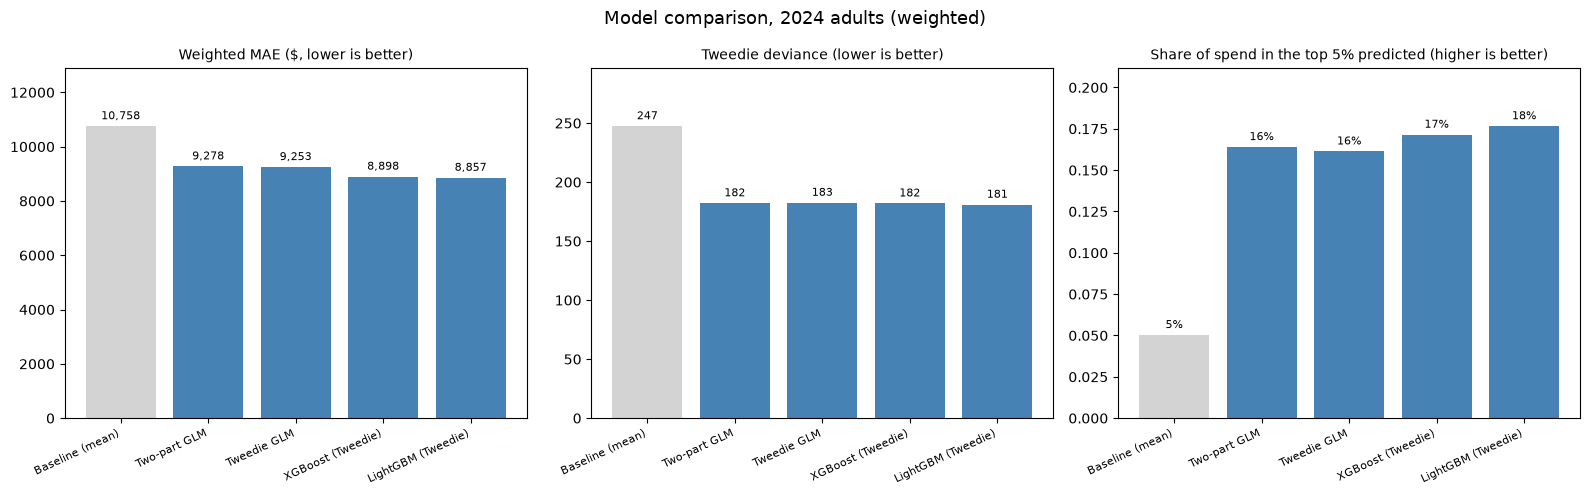

In [14]:
# Metric comparison, all 2024 adults
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [("weighted_MAE", "Weighted MAE ($, lower is better)", "{:,.0f}"),
           ("tweedie_deviance", "Tweedie deviance (lower is better)", "{:,.0f}"),
           ("top5_capture", "Share of spend in the top 5% predicted (higher is better)", "{:.0%}")]
for ax, (col, title, fmt) in zip(axes, metrics):
    vals = results_all[col]
    bars = ax.bar(range(len(vals)), vals.values, color=["lightgrey"] + ["steelblue"] * (len(vals) - 1))
    ax.bar_label(bars, labels=[fmt.format(v) for v in vals.values], padding=3, fontsize=8)
    ax.set_xticks(range(len(vals)))
    ax.set_xticklabels(vals.index, rotation=25, ha="right", fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, vals.max() * 1.2)
fig.suptitle("Model comparison, 2024 adults (weighted)", fontsize=13)
fig.tight_layout()
plt.show()

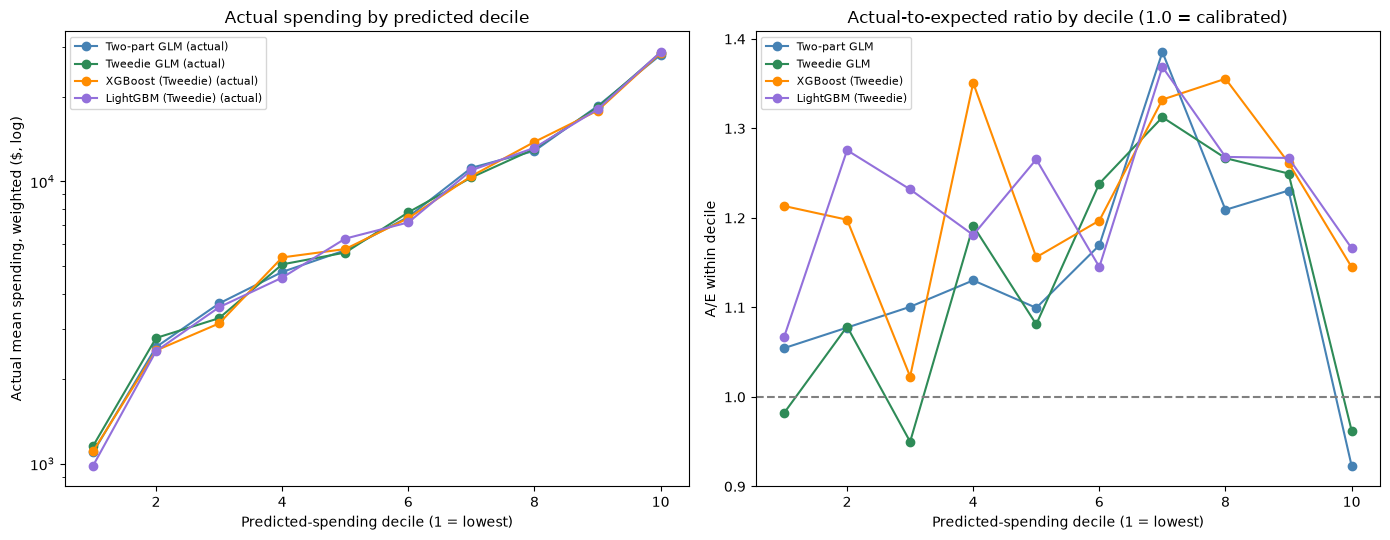

In [15]:
# Calibration: actual vs predicted spending by predicted decile, all 2024 adults
def decile_table(y, p, w):
    order = np.argsort(p)
    cum = np.cumsum(w[order]) / w.sum()
    bins = np.minimum((cum * 10).astype(int), 9)
    d = pd.DataFrame({"y": y[order], "p": p[order], "w": w[order], "bin": bins})
    g = d.groupby("bin").apply(
        lambda x: pd.Series({"actual": np.average(x.y, weights=x.w),
                             "predicted": np.average(x.p, weights=x.w)}),
        include_groups=False,
    )
    return g

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, color in zip(["Two-part GLM", "Tweedie GLM", "XGBoost (Tweedie)", "LightGBM (Tweedie)"],
                       ["steelblue", "seagreen", "darkorange", "mediumpurple"]):
    t = decile_table(test_raw["total_exp"].values, preds_all[name], test_raw["weight"].values)
    axes[0].plot(t.index + 1, t["actual"], marker="o", color=color, label=f"{name} (actual)")
    axes[1].plot(t.index + 1, t["actual"] / t["predicted"], marker="o", color=color, label=name)
axes[0].set_yscale("log")
axes[0].set_xlabel("Predicted-spending decile (1 = lowest)")
axes[0].set_ylabel("Actual mean spending, weighted ($, log)")
axes[0].set_title("Actual spending by predicted decile")
axes[0].legend(fontsize=8)
axes[1].axhline(1, color="grey", ls="--")
axes[1].set_xlabel("Predicted-spending decile (1 = lowest)")
axes[1].set_ylabel("A/E within decile")
axes[1].set_title("Actual-to-expected ratio by decile (1.0 = calibrated)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

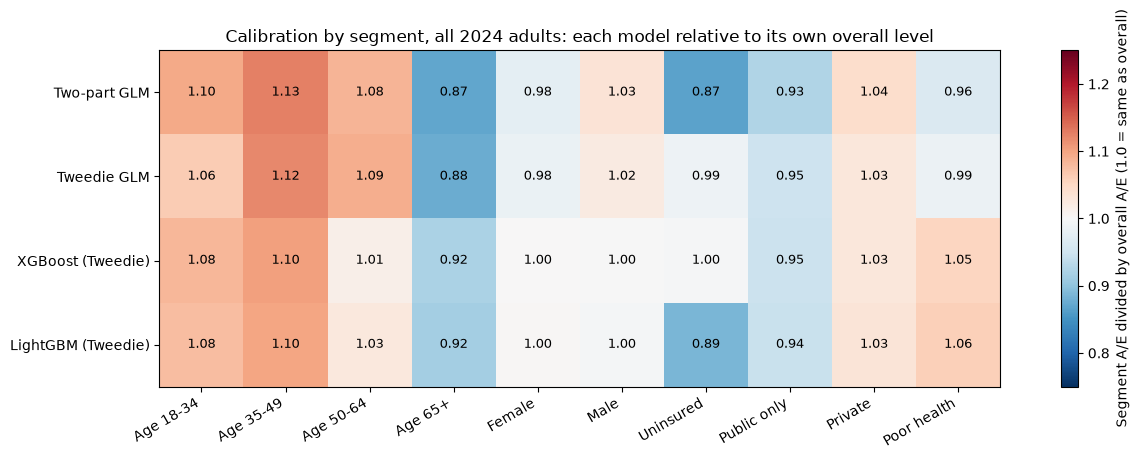

In [16]:
# A/E by segment: does each model stay calibrated for different groups?
segments = {
    "Age 18-34": test_raw["age"].between(18, 34),
    "Age 35-49": test_raw["age"].between(35, 49),
    "Age 50-64": test_raw["age"].between(50, 64),
    "Age 65+": test_raw["age"] >= 65,
    "Female": test_raw["sex"] == "Female",
    "Male": test_raw["sex"] == "Male",
    "Uninsured": test_raw["coverage"] == "Uninsured",
    "Public only": test_raw["coverage"] == "Public only",
    "Private": test_raw["coverage"] == "Private",
    "Poor health": test_raw["rth"].isin(["Fair", "Poor"]),
}
models_to_check = ["Two-part GLM", "Tweedie GLM", "XGBoost (Tweedie)", "LightGBM (Tweedie)"]
y_all, w_all = test_raw["total_exp"].values, test_raw["weight"].values
ae = pd.DataFrame(index=models_to_check, columns=list(segments), dtype=float)
for name in models_to_check:
    overall = np.sum(y_all * w_all) / np.sum(preds_all[name] * w_all)
    for seg, mask in segments.items():
        m = mask.values
        seg_ae = np.sum(y_all[m] * w_all[m]) / np.sum(preds_all[name][m] * w_all[m])
        ae.loc[name, seg] = seg_ae / overall  # relative to the model's own overall A/E

fig, ax = plt.subplots(figsize=(14, 4.5))
im = ax.imshow(ae.values.astype(float), cmap="RdBu_r", vmin=0.75, vmax=1.25)
ax.set_xticks(range(len(ae.columns))); ax.set_xticklabels(ae.columns, rotation=30, ha="right")
ax.set_yticks(range(len(ae.index))); ax.set_yticklabels(ae.index)
for i in range(ae.shape[0]):
    for j in range(ae.shape[1]):
        ax.text(j, i, f"{ae.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Segment A/E divided by overall A/E (1.0 = same as overall)")
ax.set_title("Calibration by segment, all 2024 adults: each model relative to its own overall level")
fig.tight_layout()
plt.show()

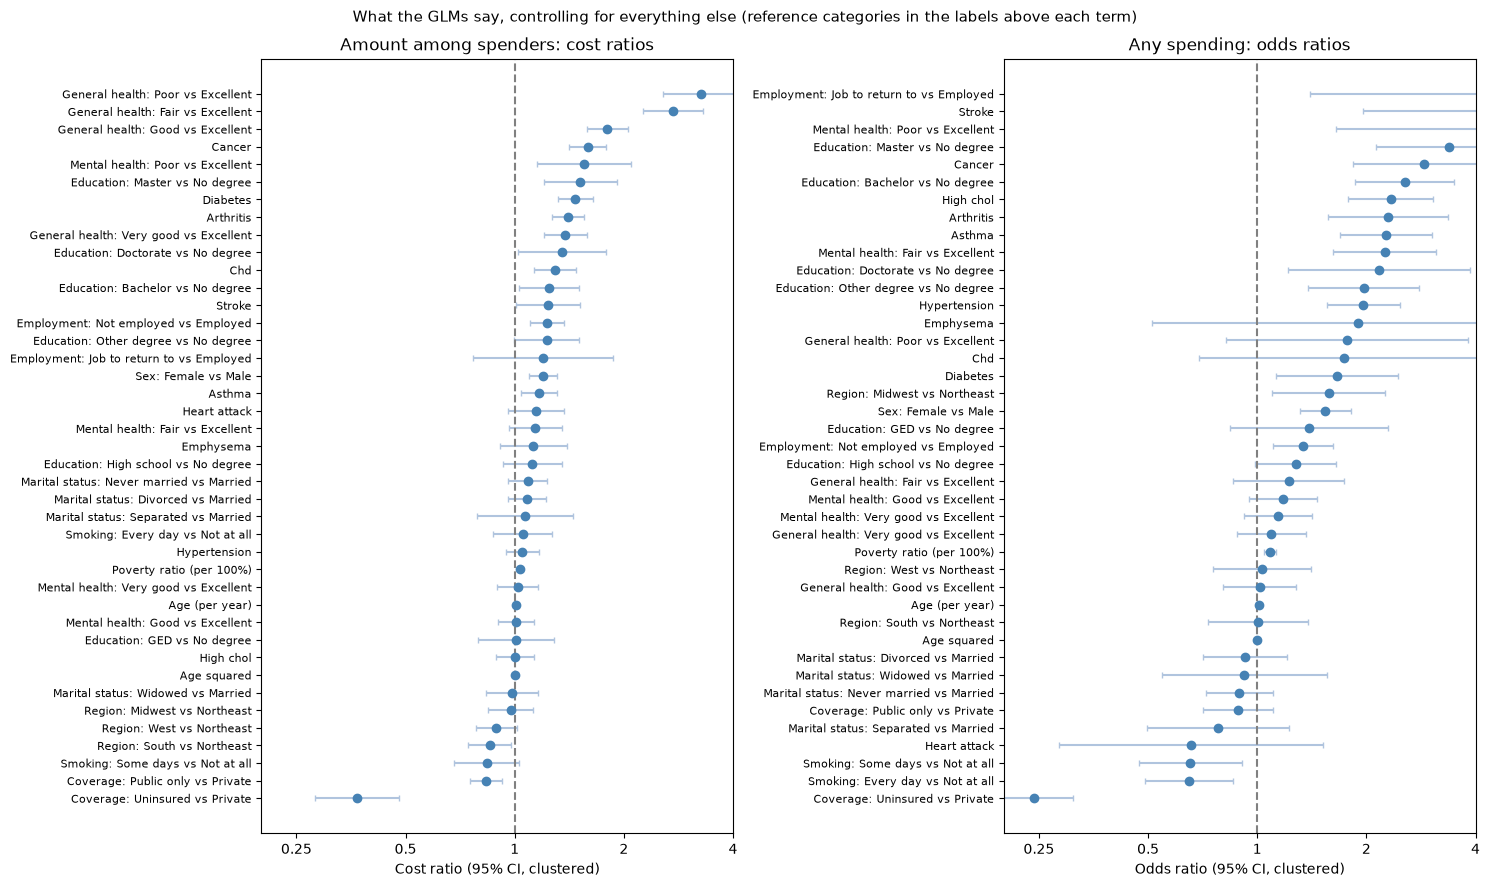

In [17]:
# GLM coefficients: rate ratios for the amount model, and odds ratios for the any-spending model
import re

NICE_NAMES = {"rth": "General health", "mnh": "Mental health", "coverage": "Coverage",
              "education": "Education", "smoking": "Smoking", "employment": "Employment",
              "marital": "Marital status", "region": "Region", "sex": "Sex",
              "age": "Age (per year)", "age2": "Age squared", "pov100": "Poverty ratio (per 100%)"}

def pretty_term(term):
    m = re.match(r"C\((\w+), Treatment\('([^']+)'\)\)\[T\.([^\]]+)\]", term)
    if m:
        var, ref, level = m.groups()
        return f"{NICE_NAMES.get(var, var)}: {level} vs {ref}"
    return NICE_NAMES.get(term, term.replace("_", " ").capitalize())

fig, axes = plt.subplots(1, 2, figsize=(15, 9))
for ax, table, title, xlabel in [
    (axes[0], part2_table, "Amount among spenders: cost ratios", "Cost ratio (95% CI, clustered)"),
    (axes[1], part1_table, "Any spending: odds ratios", "Odds ratio (95% CI, clustered)"),
]:
    col = table.columns[0]
    t = table.sort_values(col)
    y = np.arange(len(t))
    ax.errorbar(t[col], y, xerr=[t[col] - t["ci_low"], t["ci_high"] - t[col]],
                fmt="o", color="steelblue", ecolor="lightsteelblue", capsize=2)
    ax.axvline(1, color="grey", ls="--")
    ax.set_yticks(y)
    ax.set_yticklabels([pretty_term(s) for s in t.index], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlim(0.2, 4)
    ax.set_xticks([0.25, 0.5, 1, 2, 4])
    ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"])
    ax.minorticks_off()
    ax.set_xlabel(xlabel)
    ax.set_title(title)
fig.suptitle("What the GLMs say, controlling for everything else (reference categories in the labels above each term)", fontsize=11)
fig.tight_layout()
plt.show()

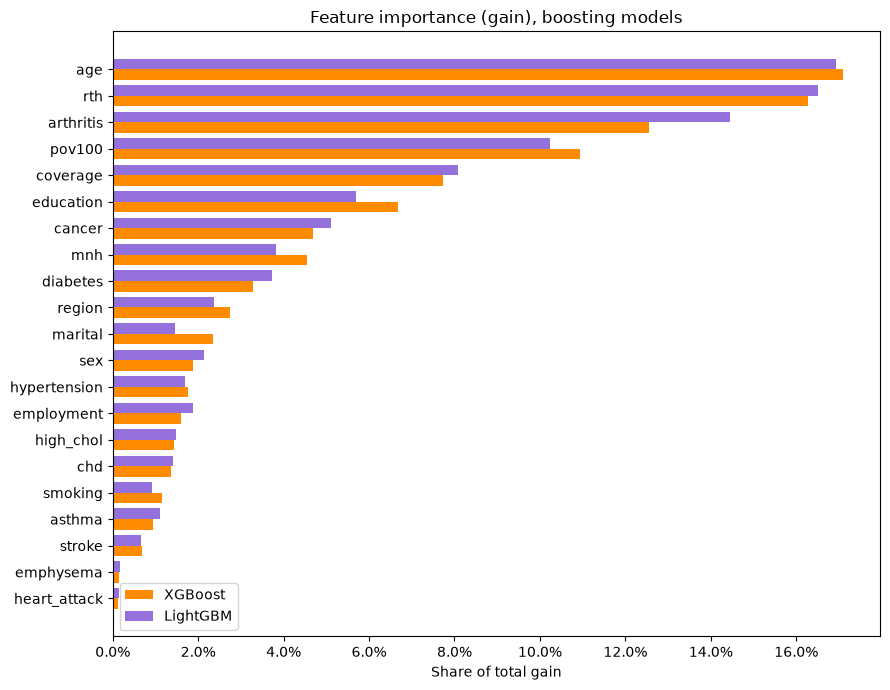

In [18]:
# Which features do the boosting models rely on? Gain-based importance from XGBoost and LightGBM
xgb_gain = pd.Series(xgb_model.get_booster().get_score(importance_type="total_gain"))
xgb_gain = xgb_gain.reindex(FEATURES).fillna(0)
lgb_gain = pd.Series(lgb_model.booster_.feature_importance(importance_type="gain"), index=FEATURES)

imp = pd.DataFrame({
    "XGBoost": xgb_gain / xgb_gain.sum(),
    "LightGBM": lgb_gain / lgb_gain.sum(),
}).sort_values("XGBoost")

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(imp))
ax.barh(y - 0.2, imp["XGBoost"], 0.4, color="darkorange", label="XGBoost")
ax.barh(y + 0.2, imp["LightGBM"], 0.4, color="mediumpurple", label="LightGBM")
ax.set_yticks(y)
ax.set_yticklabels(imp.index)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("Share of total gain")
ax.set_title("Feature importance (gain), boosting models")
ax.legend()
fig.tight_layout()
plt.show()

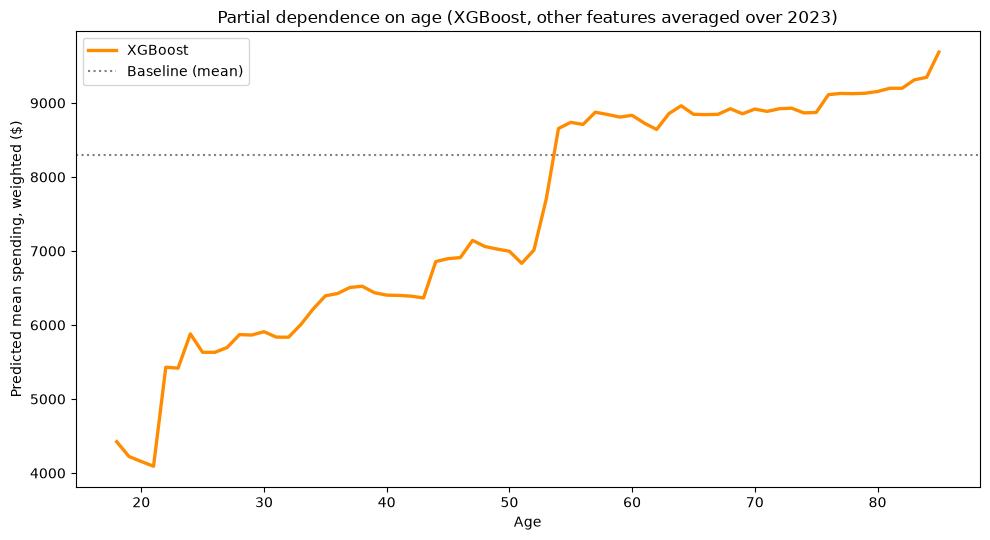

In [19]:
# Partial dependence on age: how the XGBoost prediction changes with age, other features averaged over 2023
age_grid = np.arange(18, 86)
pd_curve = []
for a in age_grid:
    Xa = X_train.copy()
    Xa["age"] = a
    pd_curve.append(np.average(xgb_model.predict(Xa[FEATURES]), weights=w_train))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(age_grid, pd_curve, color="darkorange", lw=2.4, label="XGBoost")
ax.axhline(baseline_value, ls=":", color="grey", label="Baseline (mean)")
ax.set_xlabel("Age")
ax.set_ylabel("Predicted mean spending, weighted ($)")
ax.set_title("Partial dependence on age (XGBoost, other features averaged over 2023)")
ax.legend()
fig.tight_layout()
plt.show()

### Uncertainty: bootstrap intervals for the metrics

Resampling the 2024 people (with replacement, 300 times) gives a range for each metric. A difference that falls inside that range shouldn't be read as a real gap.

In [20]:
rng = np.random.default_rng(SEED)
y_b, w_b = test_raw["total_exp"].values, test_raw["weight"].values
boot_idx = [rng.integers(0, len(y_b), len(y_b)) for _ in range(300)]

def bootstrap_metrics(p):
    maes, devs = [], []
    for idx in boot_idx:
        maes.append(weighted_mae(y_b[idx], p[idx], w_b[idx]))
        devs.append(mean_tweedie_deviance(y_b[idx], p[idx], sample_weight=w_b[idx], power=TWEEDIE_POWER))
    return np.percentile(maes, [2.5, 97.5]), np.percentile(devs, [2.5, 97.5])

rows = []
for name in predictions:
    mae_ci, dev_ci = bootstrap_metrics(preds_all[name])
    rows.append({"model": name,
                 "MAE 95% interval": f"{mae_ci[0]:,.0f} to {mae_ci[1]:,.0f}",
                 "deviance 95% interval": f"{dev_ci[0]:.1f} to {dev_ci[1]:.1f}"})
print(pd.DataFrame(rows).set_index("model").to_string())

                    MAE 95% interval deviance 95% interval
model                                                     
Baseline (mean)     10,422 to 11,180        237.7 to 258.9
Two-part GLM          8,944 to 9,653        174.3 to 191.9
Tweedie GLM           8,914 to 9,630        175.0 to 192.3
XGBoost (Tweedie)     8,563 to 9,275        173.6 to 192.2
LightGBM (Tweedie)    8,526 to 9,234        172.4 to 191.0


### Ranking: how well does each model find the big spenders?

The gains curve sorts people from the model's highest prediction down, then plots the share of total spending captured. A perfect ranking (sorted by actual spending) is the upper bound.

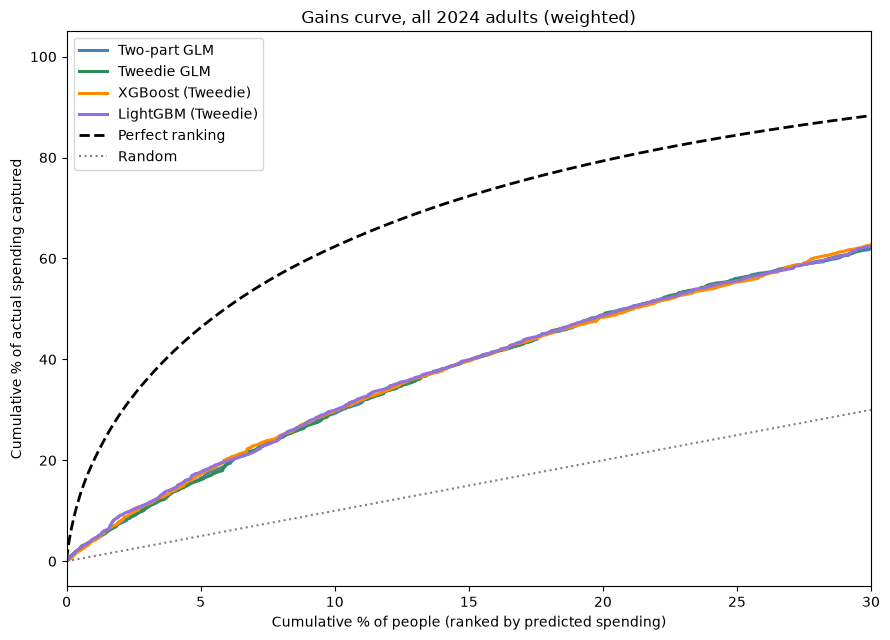

Top 5% capture with a perfect ranking: 46.3%


In [21]:
def gains_curve(y, p, w):
    order = np.argsort(-p)
    share_people = np.cumsum(w[order]) / w.sum()
    share_spend = np.cumsum(y[order] * w[order]) / np.sum(y * w)
    return share_people, share_spend

fig, ax = plt.subplots(figsize=(9, 6.5))
for name, color in zip(["Two-part GLM", "Tweedie GLM", "XGBoost (Tweedie)", "LightGBM (Tweedie)"],
                       ["steelblue", "seagreen", "darkorange", "mediumpurple"]):
    sp, ss = gains_curve(y_all, preds_all[name], w_all)
    ax.plot(sp * 100, ss * 100, lw=2.2, color=color, label=name)
sp, ss = gains_curve(y_all, y_all.astype(float), w_all)
ax.plot(sp * 100, ss * 100, lw=2, ls="--", color="black", label="Perfect ranking")
ax.plot([0, 100], [0, 100], color="grey", ls=":", label="Random")
ax.set_xlabel("Cumulative % of people (ranked by predicted spending)")
ax.set_ylabel("Cumulative % of actual spending captured")
ax.set_title("Gains curve, all 2024 adults (weighted)")
ax.set_xlim(0, 30)
ax.legend()
fig.tight_layout()
plt.show()

top5_perfect = np.sum(y_all[np.argsort(-y_all)][np.cumsum(w_all[np.argsort(-y_all)]) / w_all.sum() <= 0.05]
                      * w_all[np.argsort(-y_all)][np.cumsum(w_all[np.argsort(-y_all)]) / w_all.sum() <= 0.05]) / np.sum(y_all * w_all)
print(f"Top 5% capture with a perfect ranking: {top5_perfect:.1%}")

### Two-part GLM: the largest effects

Rate ratios for the amount among spenders, and odds ratios for spending at all, for the terms that matter most. The full tables are in the GLM cells above.

In [22]:
key = ["C(coverage, Treatment('Private'))[T.Uninsured]", "C(rth, Treatment('Excellent'))[T.Poor]",
       "C(rth, Treatment('Excellent'))[T.Fair]", "C(smoking, Treatment('Not at all'))[T.Every day]",
       "C(sex, Treatment('Male'))[T.Female]", "hypertension", "cancer", "chd", "emphysema",
       "C(employment, Treatment('Employed'))[T.Not employed]", "age"]
summary = pd.DataFrame({
    "odds_ratio_any_spend": part1_table.reindex(key)["odds_ratio"],
    "cost_ratio_amount": part2_table.reindex(key)["cost_ratio"],
})
print(summary.round(3).to_string())

                                                      odds_ratio_any_spend  cost_ratio_amount
C(coverage, Treatment('Private'))[T.Uninsured]                       0.243              0.368
C(rth, Treatment('Excellent'))[T.Poor]                               1.768              3.262
C(rth, Treatment('Excellent'))[T.Fair]                               1.220              2.729
C(smoking, Treatment('Not at all'))[T.Every day]                     0.650              1.051
C(sex, Treatment('Male'))[T.Female]                                  1.541              1.197
hypertension                                                         1.963              1.051
cancer                                                               2.880              1.589
chd                                                                  1.740              1.293
emphysema                                                            1.894              1.126
C(employment, Treatment('Employed'))[T.Not employed]        

## 12. Save the results

The metrics are saved to `data/processed/`, which git ignores. The table can be copied into the README later.

In [23]:
from pathlib import Path
out_dir = Path('..') / 'data' / 'processed'
out_dir.mkdir(parents=True, exist_ok=True)
pd.concat({'all_2024': results_all, 'not_in_2023': results_new}, axis=0).to_csv(out_dir / 'model_metrics.csv')
print('saved', out_dir / 'model_metrics.csv')


saved ../data/processed/model_metrics.csv


## 13. Findings

**Accuracy.** Every model beats the baseline by a wide margin. The baseline's weighted MAE is about $10,700 on 2024 adults. The two-part GLM gets to about $9,300, the Tweedie GLM to about $9,250, XGBoost to about $8,900, and LightGBM to about $8,860. The bootstrap intervals overlap a lot. Most of the MAE and deviance differences between the four models fall inside the noise, so the honest summary is that the boosting models are slightly better, and the GLMs are close behind.

**Level shift.** All models under-predict total 2024 spending, with overall A/E between 1.08 and 1.23. The baseline is at 1.16, and the cause is a real change in the data, not the models: the weighted mean for adults went from about $8,425 in 2023 to about $9,600 in 2024, up 14%. The models learned 2023 levels. In a forecast year, that gap has to be handled with an explicit trend assumption, which this notebook does not add.

**Calibration by segment.** Once the level shift is removed (each segment divided by the model's own overall A/E), the models are within about 10% for most groups. The GLMs under-predict adults 18 to 49 (relative A/E 1.06 to 1.13) and over-predict people 65 and older (0.87 to 0.88). Boosting narrows the 65+ gap to about 0.92, but doesn't close it.

**Ranking the big spenders.** The best models put only about 16 to 18% of spending in their top 5% of predicted people. A perfect ranking would capture about 46%. The gains curve shows the models do well overall but find the highest spenders poorly, which matters if the purpose is to identify high-cost cases.

**What drives spending.** The boosting models agree on the top features: age, self-rated health, arthritis, the poverty ratio, and insurance coverage. In the GLMs, controlling for everything else:
- **Uninsured:** the odds of spending at all are about a quarter of the privately insured (odds ratio 0.24), and spending among spenders is about 37% of the privately insured (cost ratio 0.37).
- **Poor self-rated health:** the odds of spending are 1.77 times higher, and spending among spenders is 3.26 times higher. Fair health is 2.73 times higher.
- **Cancer:** the odds of spending are 2.88 times higher, and the cost ratio is 1.59.
- **Women:** the odds of spending are 1.54 times higher, and the cost ratio is 1.20.
- **Every-day smokers:** the odds of spending are 0.65 times, and the cost ratio is about 1.05. Smoking shows a lower chance of spending, but no clear cost effect once health is controlled.

These are associations, and the diagnoses and health ratings are measured in the same year as spending.

## 14. Limitations

- **Concurrent model.** Health, diagnoses, and employment are measured in the same year as the spending they're predicting. This describes a relationship, and it can't be used directly to forecast next year.
- **No trend adjustment.** The 14% rise in spending between 2023 and 2024 is left in. A production model would need an explicit assumption for the trend.
- **Standard errors are approximate.** The GLMs use clustered standard errors. statsmodels warns that clustering isn't fully supported with frequency weights, so the GLM intervals are approximate. The bootstrap resamples people, not PSUs, so its intervals are probably too narrow.
- **Light tuning.** The boosting settings were chosen up front, with early stopping on 20% of 2023. There was no cross-validated search, and the final boosting models weren't refit on all of 2023.
- **One test year.** The results are for 2024 only.
- **Adults only.** Children were excluded, since several questions are adult-only.
- **Race and ethnicity** were excluded from the models, and no fairness check was run.

## 15. Next steps

1. Add a trend or level adjustment for forecasting, and state the assumption.
2. Run a grouped cross-validation on 2023 (grouped by PSU) to tune the boosting models, instead of a single validation split.
3. Refit the boosting models on all of 2023 at the chosen number of trees.
4. Build a separate model for children.
5. Test the fairness of the results across race and ethnicity, using the held-out segments as the check.